# Project 2: Defining and Solving Reinforcement Learning Environments

Author: Minuu Lakshmi Shanmugam, B01157604, CS 4/565 Introduction to AI, Fall 2026.

This notebook defines a grid navigation environment in Gymnasium form, validates it with a random agent, solves it with Q learning and with SARSA, tunes four hyperparameters, and saves the learned tables. Run the cells from top to bottom. All plots and pickle files are written to the outputs folder.

In [1]:
from pathlib import Path
import pickle
import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = Path("outputs")
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

## Part 1: Environment design

The task is grid navigation. The grid has 5 rows and 4 columns, so 20 positions. Each position can be combined with 8 collected states, one for each subset of the three special cells, so the observation space has 160 states. This expansion matters. If a special reward could be collected only once, and the state recorded only the position, the future reward would depend on history that the state does not record. Recording the collected set in the state keeps the task Markovian.

Actions are down, up, right, and left. The start is (0, 0). The goal is (4, 3). Special cells are (0, 3) with reward 1.0, (2, 3) with reward 2.0, and (3, 2) with reward 3.0. Each special reward is collected only on the first visit in an episode. An ordinary step costs 0.1. Reaching the goal gives 5.0 and ends the episode. An episode is also cut off at 100 steps. A move into a wall leaves the agent in place and costs 0.1.

The best possible deterministic episode collects all three specials and then reaches the goal in 9 steps, for total reward 10.5. That path is (0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 2), (3, 2), (4, 2), (4, 3).

In [2]:
SPECIALS = [(0, 3), (2, 3), (3, 2)]
SPECIAL_VALUES = { (0, 3): 1.0, (2, 3): 2.0, (3, 2): 3.0 }

class GridEnvironment(gym.Env):
    metadata = {"render_modes": ["human", "rgb_array"], "render_fps": 4}
    ACTION_DELTAS = {0: (1, 0), 1: (-1, 0), 2: (0, 1), 3: (0, -1)}
    ACTION_NAMES = {0: "down", 1: "up", 2: "right", 3: "left"}
    # Initialise the environment: spaces, start, goal, special cells, and step limit.
    def __init__(self, stochastic=False, max_episode_steps=100, render_mode=None):
        super().__init__()
        self.rows = 5
        self.cols = 4
        self.stochastic = stochastic
        self.max_episode_steps = max_episode_steps
        self.render_mode = render_mode
        self.observation_space = spaces.Discrete(self.rows * self.cols * 8)
        self.action_space = spaces.Discrete(4)
        self.start_pos = (0, 0)
        self.goal_pos = (4, 3)
        self.special_rewards = dict(SPECIAL_VALUES)
        self.agent_pos = self.start_pos
        self.timestep = 0
        self.mask = 0
    def _encode(self):
        return (self.agent_pos[0] * self.cols + self.agent_pos[1]) * 8 + self.mask
    def _move(self, action):
        dr, dc = self.ACTION_DELTAS[int(action)]
        row = int(np.clip(self.agent_pos[0] + dr, 0, self.rows - 1))
        col = int(np.clip(self.agent_pos[1] + dc, 0, self.cols - 1))
        self.agent_pos = (row, col)
    # Reset to the start position with an empty collected set.
    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.agent_pos = self.start_pos
        self.timestep = 0
        self.mask = 0
        return self._encode(), {"position": self.agent_pos, "mask": self.mask}
    # Apply one action, update position and collected set, and return reward and flags.
    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")
        actual_action = int(action)
        if self.stochastic:
            probabilities = np.full(self.action_space.n, 0.10)
            probabilities[actual_action] = 0.70
            actual_action = int(self.np_random.choice(self.action_space.n, p=probabilities))
        self._move(actual_action)
        self.timestep += 1
        terminated = self.agent_pos == self.goal_pos
        truncated = self.timestep >= self.max_episode_steps and not terminated
        if terminated:
            reward = 5.0
        elif self.agent_pos in self.special_rewards:
            idx = SPECIALS.index(self.agent_pos)
            if not (self.mask >> idx) & 1:
                reward = self.special_rewards[self.agent_pos]
                self.mask |= (1 << idx)
            else:
                reward = -0.1
        else:
            reward = -0.1
        observation = self._encode()
        info = {"position": self.agent_pos, "requested_action": int(action), "actual_action": actual_action, "mask": self.mask}
        return observation, reward, terminated, truncated, info
    # Draw the grid, or return an image array when rgb array mode is requested.
    def render(self):
        image = np.ones((self.rows, self.cols, 3), dtype=float)
        for (row, col), reward in self.special_rewards.items():
            image[row, col] = (1.0, 0.85 - 0.1 * reward, 0.3)
        image[self.goal_pos] = (0.2, 0.75, 0.3)
        image[self.agent_pos] = (0.15, 0.35, 0.95)
        if self.render_mode == "rgb_array":
            return (image * 255).astype(np.uint8)
        plt.figure(figsize=(4, 5))
        plt.imshow(image)
        plt.xticks(range(self.cols))
        plt.yticks(range(self.rows))
        plt.grid(color="black", linewidth=0.5)
        plt.title("Stochastic environment" if self.stochastic else "Deterministic environment")
        plt.show()

class DeterministicGridEnvironment(GridEnvironment):
    def __init__(self, **kwargs):
        super().__init__(stochastic=False, **kwargs)

class StochasticGridEnvironment(GridEnvironment):
    def __init__(self, **kwargs):
        super().__init__(stochastic=True, **kwargs)



## Validation with a random agent

Both environments pass the Gymnasium environment checker. The checker confirms that observations belong to the observation space, actions belong to the action space, and reset and step return values in the expected form. A random agent is then run for 40 timesteps in each environment. If an episode ends during the trace, the environment is reset and the trace continues. The full traces are printed here and reproduced in the report appendix.

In [3]:
deterministic_env = DeterministicGridEnvironment()
stochastic_env = StochasticGridEnvironment()

check_env(deterministic_env)
check_env(stochastic_env)
print("Both environments passed check_env.")

Both environments passed check_env.


/home/hatch/workspace/ai-project2/venv/lib/python3.12/site-packages/gymnasium/utils/env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


In [4]:
def random_agent_trace(env, steps=40, seed=2026):
    observation, info = env.reset(seed=seed)
    env.action_space.seed(seed)
    trace = []
    episode = 1
    for timestep in range(1, steps + 1):
        action = env.action_space.sample()
        next_observation, reward, terminated, truncated, info = env.step(action)
        trace.append({"timestep": timestep, "episode": episode, "state": int(observation), "position": info["position"], "action": int(action), "next_state": int(next_observation), "reward": float(reward), "terminated": bool(terminated), "truncated": bool(truncated)})
        observation = next_observation
        if terminated or truncated:
            episode += 1
            observation, info = env.reset()
    return trace

# Train with Q learning: off policy update toward the best next action value.
# Termination and truncation both end the episode, with no future value added after either flag.

def stochastic_frequency_check(trials=1000, seed=2026):
    # Empirical check of stochastic transitions, separate from learning.
    # Start at (1, 1) so all four actual actions lead to distinct positions,
    # with no wall clipping and no special cell. Request right on every trial.
    env = StochasticGridEnvironment()
    counts = {0: 0, 1: 0, 2: 0, 3: 0}
    for trial in range(trials):
        env.reset(seed=seed + trial)
        env.agent_pos = (1, 1)
        env.mask = 0
        env.timestep = 0
        _, _, _, _, info = env.step(2)
        counts[info["actual_action"]] += 1
    return counts


deterministic_trace = random_agent_trace(DeterministicGridEnvironment(), steps=40)
stochastic_trace = random_agent_trace(StochasticGridEnvironment(), steps=40)

print("Deterministic trace (40 timesteps)")
for row in deterministic_trace:
    print(row)

print("\nStochastic trace (40 timesteps)")
for row in stochastic_trace:
    print(row)

Deterministic trace (40 timesteps)
{'timestep': 1, 'episode': 1, 'state': 0, 'position': (0, 0), 'action': 3, 'next_state': 0, 'reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 2, 'episode': 1, 'state': 0, 'position': (1, 0), 'action': 0, 'next_state': 32, 'reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 3, 'episode': 1, 'state': 32, 'position': (2, 0), 'action': 0, 'next_state': 64, 'reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 4, 'episode': 1, 'state': 64, 'position': (2, 1), 'action': 2, 'next_state': 72, 'reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 5, 'episode': 1, 'state': 72, 'position': (1, 1), 'action': 1, 'next_state': 40, 'reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 6, 'episode': 1, 'state': 40, 'position': (0, 1), 'action': 1, 'next_state': 8, 'reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 7, 'episode': 1, 'state': 8, 'position': (1, 1), '

## Stochastic transition check

This check is separate from learning. Start at (1, 1) so all four actual actions lead to distinct positions, with no wall clipping and no special cell. Request right on every trial, for 1000 trials, with seed 2026. Expected frequencies are 0.70 for right and 0.10 for each other action. Observed frequencies should be close to those values, with sampling variation expected.

In [5]:
freq_counts = stochastic_frequency_check(trials=1000, seed=2026)
print("Stochastic frequency check, requested right, start (1, 1), 1000 trials:")
for _action, _name in [(0, "down"), (1, "up"), (2, "right"), (3, "left")]:
    print(_name, freq_counts[_action], freq_counts[_action] / 1000)

Stochastic frequency check, requested right, start (1, 1), 1000 trials:
down 106 0.106
up 90 0.09
right 712 0.712
left 92 0.092


## Part 2: Q learning

One Q learning implementation is used for both environments. It starts with a table of zeros, chooses actions with epsilon greedy exploration, and updates with learning rate alpha and discount factor gamma. Terminal transitions do not add a future value. Epsilon starts at 1.0, decays by 0.99 per episode, and is floored at 0.05. Training uses 500 episodes and seed 2026. The two learned tables are saved separately and reloaded to confirm they match.

In [6]:
def train_q_learning(env, episodes=500, alpha=0.3, gamma=0.9, epsilon_start=1.0, epsilon_min=0.05, epsilon_decay=0.99, seed=2026):
    q_table = np.zeros((env.observation_space.n, env.action_space.n), dtype=float)
    rewards = []
    epsilons = []
    epsilon = epsilon_start
    rng = np.random.default_rng(seed)
    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        total_reward = 0.0
        while True:
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                best_actions = np.flatnonzero(q_table[state] == q_table[state].max())
                action = int(rng.choice(best_actions))
            next_state, reward, terminated, truncated, _ = env.step(action)
            future_value = 0.0 if (terminated or truncated) else np.max(q_table[next_state])
            target = reward + gamma * future_value
            q_table[state, action] += alpha * (target - q_table[state, action])
            total_reward += reward
            state = next_state
            if terminated or truncated:
                break
        rewards.append(total_reward)
        epsilons.append(epsilon)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)
    return q_table, np.asarray(rewards), np.asarray(epsilons)

# Train with SARSA: on policy update toward the action actually taken next.

q_deterministic, rewards_deterministic, eps_deterministic = train_q_learning(DeterministicGridEnvironment(), seed=2026)
q_stochastic, rewards_stochastic, eps_stochastic = train_q_learning(StochasticGridEnvironment(), seed=2026)

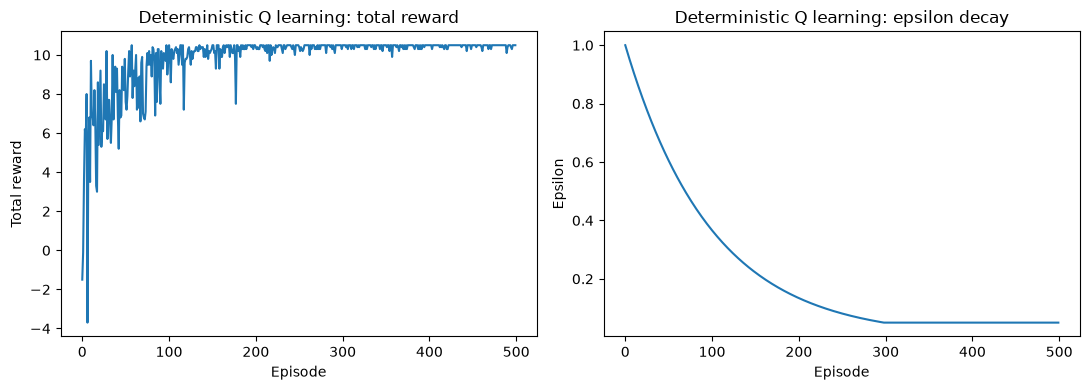

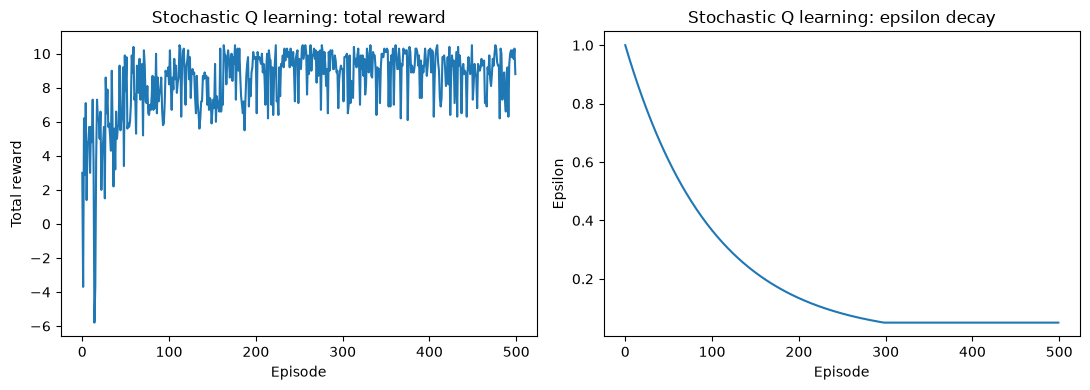

In [7]:
def save_learning_plot(rewards, epsilons, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(rewards)
    axes[0].set(title=f"{title}: total reward", xlabel="Episode", ylabel="Total reward")
    axes[1].plot(epsilons)
    axes[1].set(title=f"{title}: epsilon decay", xlabel="Episode", ylabel="Epsilon")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / filename, dpi=160)
    plt.show()

save_learning_plot(rewards_deterministic, eps_deterministic, "Deterministic Q learning", "q_learning_deterministic.png")
save_learning_plot(rewards_stochastic, eps_stochastic, "Stochastic Q learning", "q_learning_stochastic.png")

In [8]:
q_table_files = {
    "deterministic": OUTPUT_DIR / "deterministic_q_table.pkl",
    "nondeterministic": OUTPUT_DIR / "nondeterministic_q_table.pkl",
}

for name, q_table in (("deterministic", q_deterministic), ("nondeterministic", q_stochastic)):
    with q_table_files[name].open("wb") as file:
        pickle.dump(q_table, file)
    with q_table_files[name].open("rb") as file:
        restored = pickle.load(file)
    assert np.array_equal(q_table, restored)

print("Saved and verified:", q_table_files)

Saved and verified: {'deterministic': PosixPath('outputs/deterministic_q_table.pkl'), 'nondeterministic': PosixPath('outputs/nondeterministic_q_table.pkl')}


## Additional algorithm: SARSA on the deterministic environment

SARSA is on policy. It updates the action that was actually taken next, rather than the best action in the next state. In this small task the difference is modest, because exploration decays and both methods converge to the same optimal path. SARSA is slightly slower on average here, which is expected for an on policy method that must learn through its own exploratory moves.

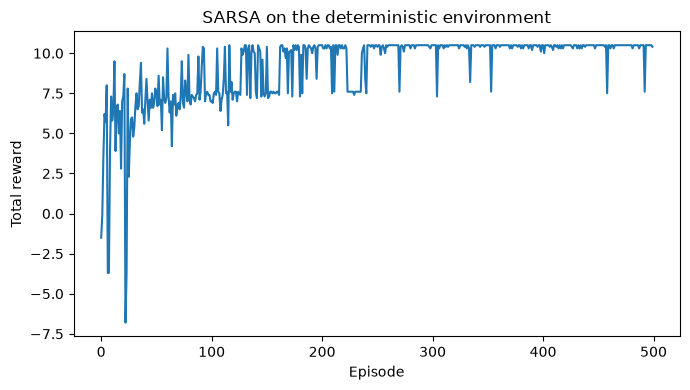

In [9]:
def train_sarsa(env, episodes=500, alpha=0.3, gamma=0.9, epsilon_start=1.0, epsilon_min=0.05, epsilon_decay=0.99, seed=2026):
    q_table = np.zeros((env.observation_space.n, env.action_space.n), dtype=float)
    rewards = []
    epsilon = epsilon_start
    rng = np.random.default_rng(seed)
    def choose_action(state, current_epsilon):
        if rng.random() < current_epsilon:
            return int(rng.integers(env.action_space.n))
        best_actions = np.flatnonzero(q_table[state] == q_table[state].max())
        return int(rng.choice(best_actions))
    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        action = choose_action(state, epsilon)
        total_reward = 0.0
        while True:
            next_state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            if terminated or truncated:
                target = reward
                q_table[state, action] += alpha * (target - q_table[state, action])
                break
            next_action = choose_action(next_state, epsilon)
            target = reward + gamma * q_table[next_state, next_action]
            q_table[state, action] += alpha * (target - q_table[state, action])
            state, action = next_state, next_action
        rewards.append(total_reward)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)
    return q_table, np.asarray(rewards)

# Run a greedy rollout with no random moves, to check that the policy reaches the goal.

q_sarsa, rewards_sarsa = train_sarsa(DeterministicGridEnvironment())
plt.figure(figsize=(7, 4))
plt.plot(rewards_sarsa)
plt.title("SARSA on the deterministic environment")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.tight_layout()
plt.savefig(PLOT_DIR / "sarsa_deterministic.png", dpi=160)
plt.show()

In [10]:
with (OUTPUT_DIR / "sarsa_q_table.pkl").open("wb") as file:
    pickle.dump(q_sarsa, file)
with (OUTPUT_DIR / "sarsa_q_table.pkl").open("rb") as file:
    restored_sarsa = pickle.load(file)
assert np.array_equal(q_sarsa, restored_sarsa)
print("Saved and verified sarsa_q_table.pkl", q_sarsa.shape)

Saved and verified sarsa_q_table.pkl (160, 4)


## Hyperparameter experiments

Four hyperparameters are tuned, one at a time, with all other values held at the base setting: alpha 0.3, gamma 0.9, epsilon decay 0.99, epsilon minimum 0.05, 500 episodes, seed 2026. Each parameter is tested at three values, so there are twelve tuning runs in total. Each comparison figure shows the 20 episode mean reward. Twelve additional detail figures show each run on its own. The report discusses every figure and recommends a setting. Alpha is included because the example code tunes it, and epsilon minimum is included because it is explicitly listed in the assignment tuning list, so the tuning set covers both the example and the assignment list.

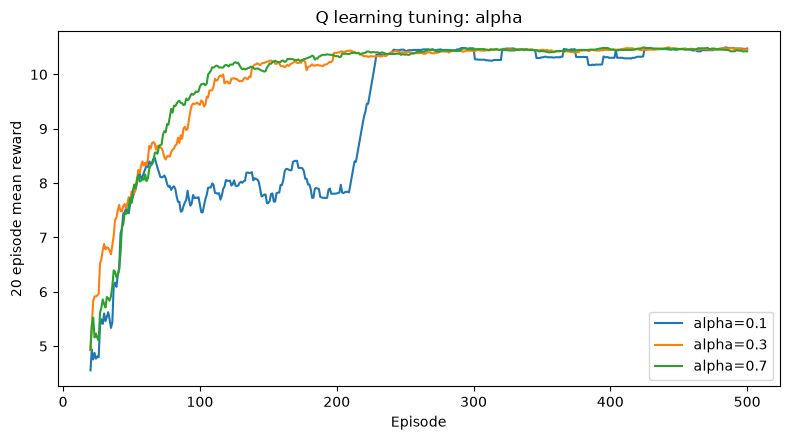

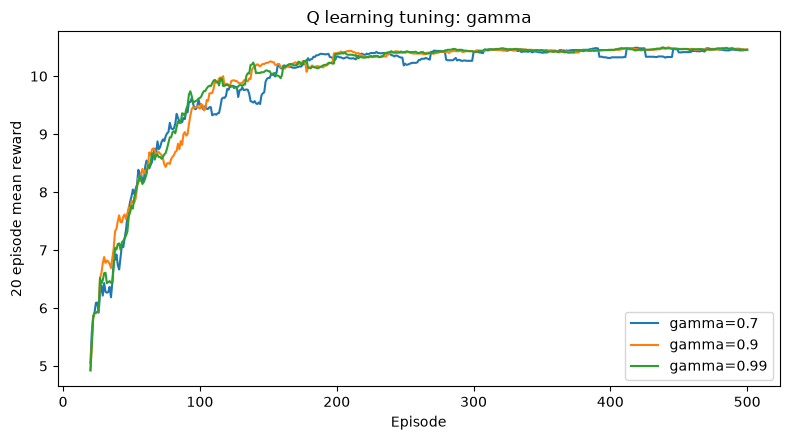

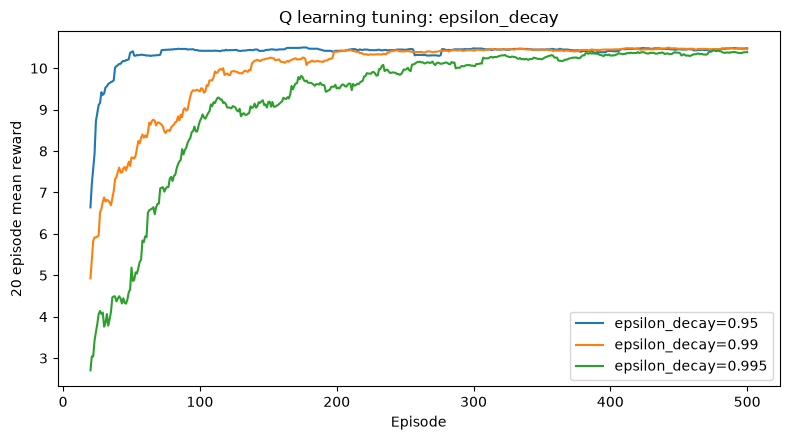

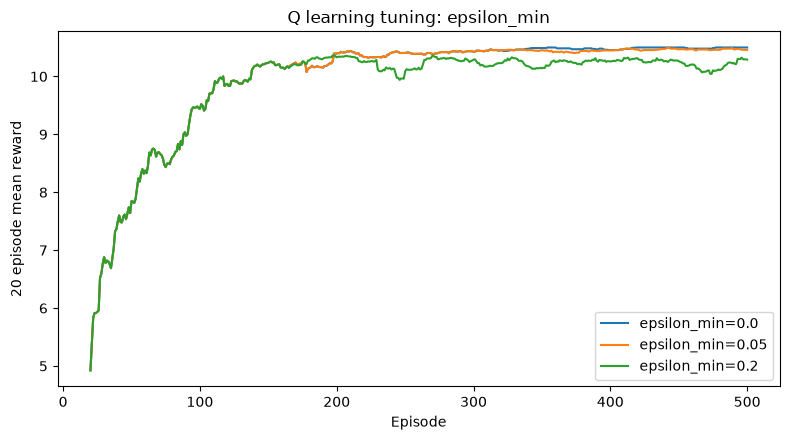

In [11]:
experiment_values = {
    "alpha": [0.1, 0.3, 0.7],
    "gamma": [0.7, 0.9, 0.99],
    "epsilon_decay": [0.95, 0.99, 0.995],
    "epsilon_min": [0.0, 0.05, 0.2],
}
base_parameters = {"alpha": 0.3, "gamma": 0.9, "epsilon_decay": 0.99, "epsilon_min": 0.05}
tuning_results = {}

for parameter, values in experiment_values.items():
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for value in values:
        parameters = dict(base_parameters)
        parameters[parameter] = value
        _, rewards, _ = train_q_learning(DeterministicGridEnvironment(), episodes=500, seed=2026, **parameters)
        tuning_results[(parameter, value)] = rewards
        moving_average = np.convolve(rewards, np.ones(20) / 20, mode="valid")
        ax.plot(np.arange(20, len(rewards) + 1), moving_average, label=f"{parameter}={value}")
    ax.set(title=f"Q learning tuning: {parameter}", xlabel="Episode", ylabel="20 episode mean reward")
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"tuning_{parameter}.png", dpi=160)
    plt.show()

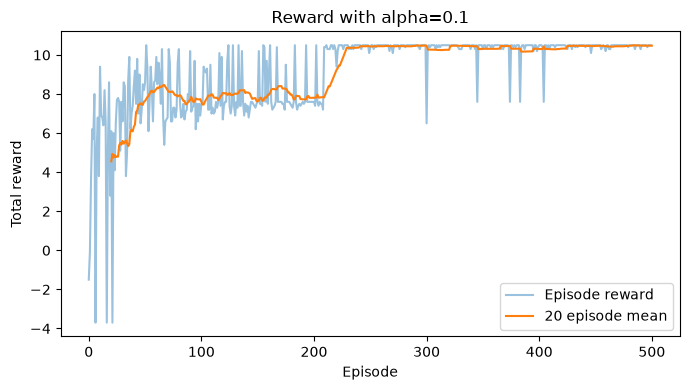

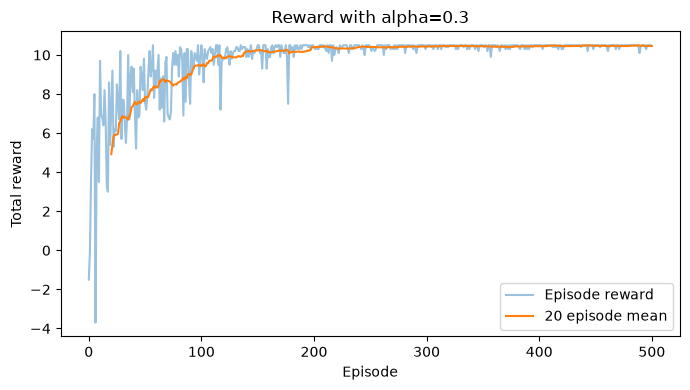

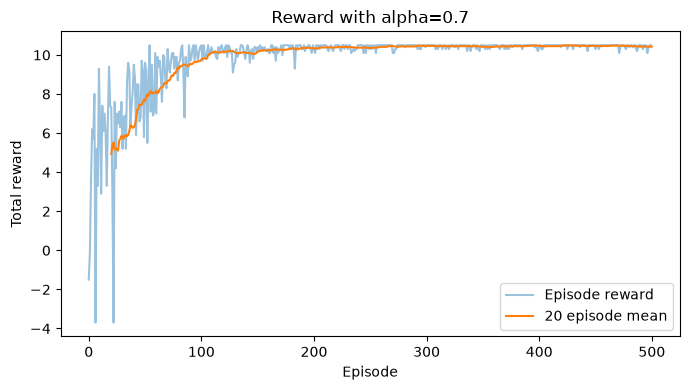

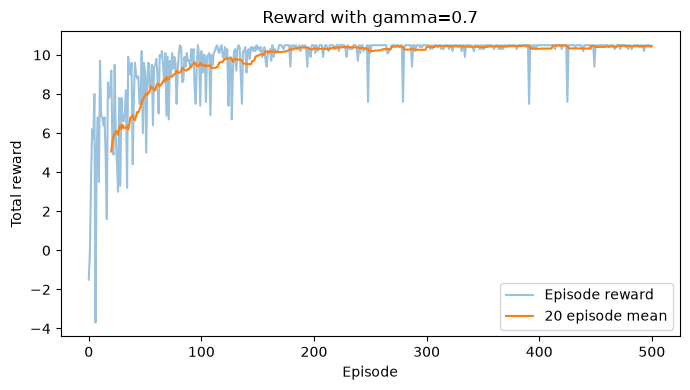

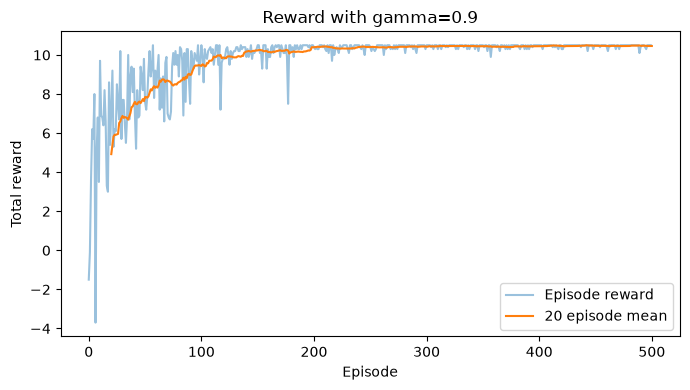

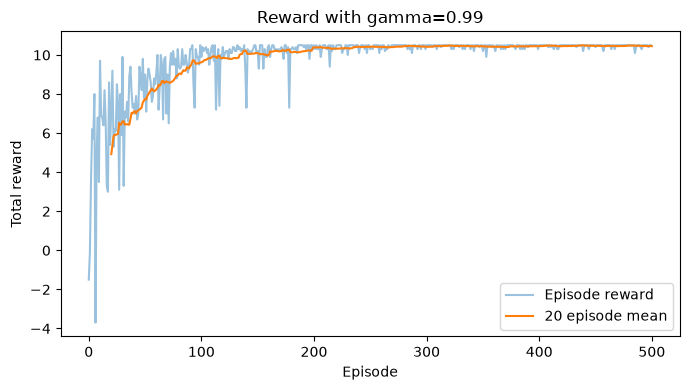

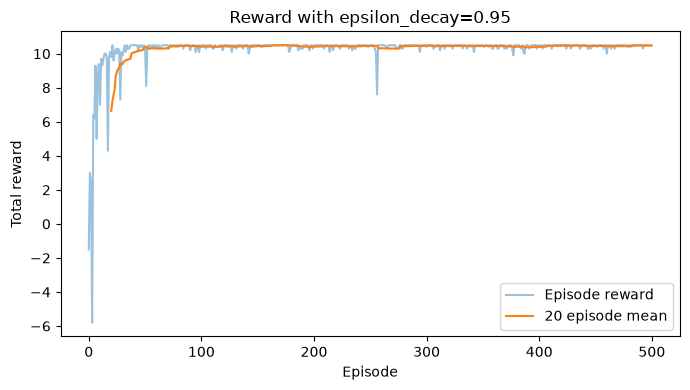

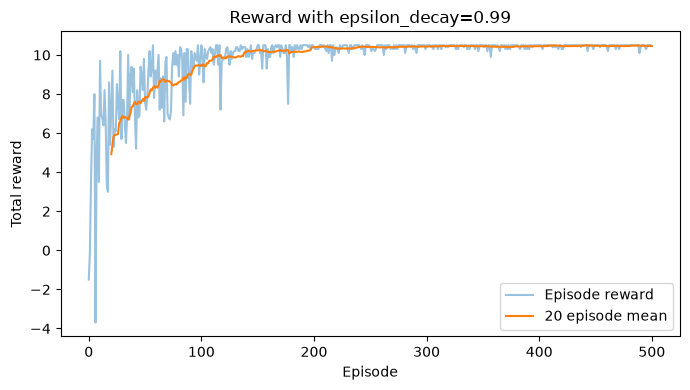

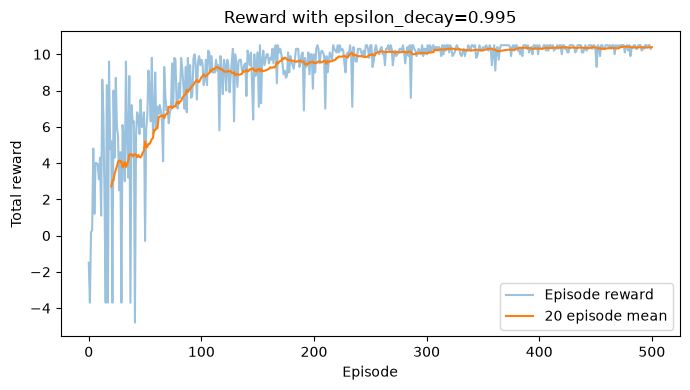

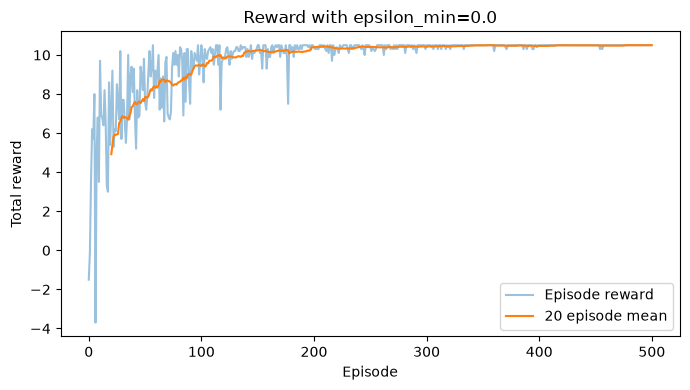

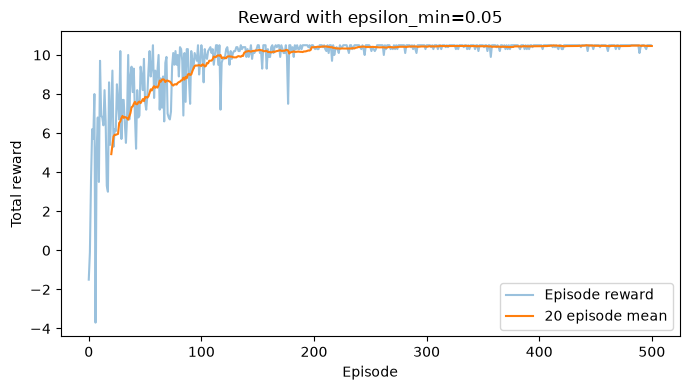

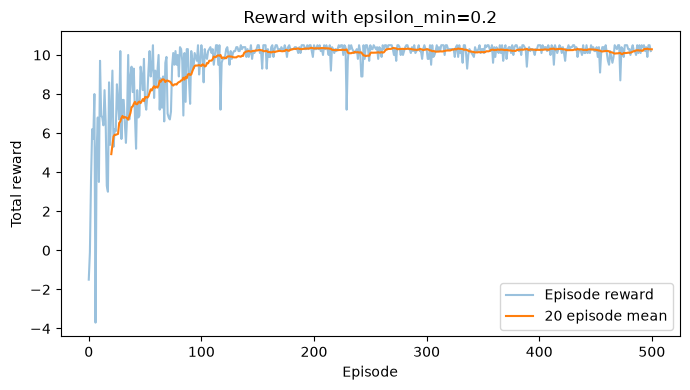

In [12]:
for index, ((parameter, value), rewards) in enumerate(tuning_results.items()):
    plt.figure(figsize=(7, 4))
    plt.plot(rewards, alpha=0.45, label="Episode reward")
    moving_average = np.convolve(rewards, np.ones(20) / 20, mode="valid")
    plt.plot(np.arange(20, len(rewards) + 1), moving_average, label="20 episode mean")
    plt.title(f"Reward with {parameter}={value}")
    plt.xlabel("Episode")
    plt.ylabel("Total reward")
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"tuning_detail_{index + 1}_{parameter}_{value}.png", dpi=160)
    plt.show()

In [13]:
def greedy_rollout(env, q_table, seed=2026):
    # Follow the best action at each step, with no random moves.
    state, _ = env.reset(seed=seed)
    positions = [env.agent_pos]
    total_reward = 0.0
    steps = 0
    terminated = False
    for _ in range(100):
        action = int(np.argmax(q_table[state]))
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        steps += 1
        positions.append(env.agent_pos)
        state = next_state
        if terminated or truncated:
            break
    return total_reward, steps, terminated, positions

print("Q learning deterministic, last 50 mean:", float(rewards_deterministic[-50:].mean()))
print("Q learning stochastic, last 50 mean:", float(rewards_stochastic[-50:].mean()))
print("SARSA deterministic, last 50 mean:", float(rewards_sarsa[-50:].mean()))
print("Greedy Q deterministic:", greedy_rollout(DeterministicGridEnvironment(), q_deterministic))
print("Greedy Q stochastic:", greedy_rollout(StochasticGridEnvironment(), q_stochastic))
print("Greedy SARSA deterministic:", greedy_rollout(DeterministicGridEnvironment(), q_sarsa))

Q learning deterministic, last 50 mean: 10.466
Q learning stochastic, last 50 mean: 8.894
SARSA deterministic, last 50 mean: 10.362
Greedy Q deterministic: (10.5, 9, True, [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 2), (3, 2), (4, 2), (4, 3)])
Greedy Q stochastic: (9.5, 19, True, [(0, 0), (0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (0, 3), (0, 2), (0, 2), (0, 3), (1, 3), (1, 2), (1, 1), (2, 1), (2, 2), (2, 3), (2, 2), (3, 2), (3, 3), (4, 3)])
Greedy SARSA deterministic: (10.5, 9, True, [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 2), (3, 2), (3, 3), (4, 3)])


## Environment images for the report

The two images below are saved for the report. They use the same grid layout as the environments above.

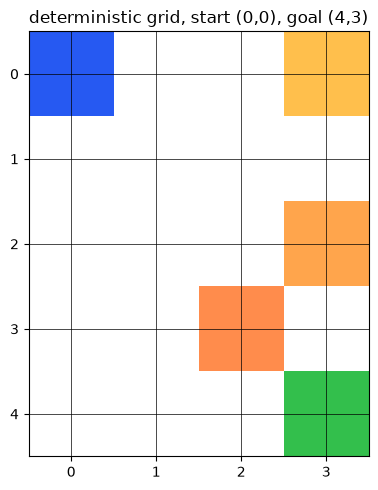

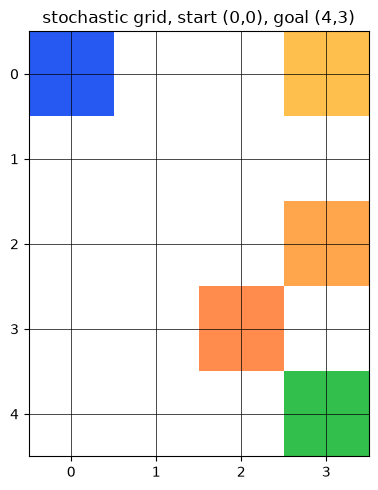

Environment images saved.


In [14]:
for _name, _env in [("deterministic", DeterministicGridEnvironment(render_mode="rgb_array")), ("stochastic", StochasticGridEnvironment(render_mode="rgb_array"))]:
    _env.reset(seed=2026)
    _img = _env.render()
    plt.figure(figsize=(4, 5))
    plt.imshow(_img)
    plt.xticks(range(4))
    plt.yticks(range(5))
    plt.grid(color="black", linewidth=0.5)
    plt.title(f"{_name} grid, start (0,0), goal (4,3)")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"env_{_name}.png", dpi=160)
    plt.show()
print("Environment images saved.")